# Seminário de Ciência de Dados - World Cup 2026

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [46]:
url = "https://raw.githubusercontent.com/EnzoAlvesBarcelosGripp/wc26-match-predictor/main/Joins%20datasets/dataset_temporal_final.csv"
df = pd.read_csv(url)

df.head()

,Unnamed: 0,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral,...,away_Rank,away_TotalPoints,home_GER,home_ATQ,home_MED,home_DEF,away_GER,away_ATQ,away_MED,away_DEF
0,0,2018-09-06,Dominica,Suriname,0.0,0.0,CONCACAF Nations League qualification,Les Abymes,Guadeloupe,True,...,153.0,1036.0,59.0,58.0,59.0,58.0,61.0,61.0,61.0,60.0
1,1,2018-09-06,Guyana,Barbados,3.0,0.0,CONCACAF Nations League qualification,Leonora,Guyana,False,...,160.0,1005.0,58.0,57.0,58.0,57.0,60.0,60.0,60.0,59.0
2,2,2018-09-06,Wales,Republic of Ireland,4.0,1.0,UEFA Nations League,Cardiff,Wales,False,...,29.0,1484.0,74.0,82.0,74.0,73.0,75.0,74.0,74.0,76.0
3,3,2018-09-06,Czech Republic,Ukraine,1.0,2.0,UEFA Nations League,Uherské Hradiště,Czech Republic,False,...,35.0,1468.0,76.0,76.0,74.0,75.0,74.0,74.0,74.0,73.0
4,4,2018-09-06,Norway,Cyprus,2.0,0.0,UEFA Nations League,Oslo,Norway,False,...,87.0,1280.0,74.0,75.0,75.0,73.0,68.0,68.0,68.0,67.0


## EDA (Analise Exploratoria dos Dados)

In [47]:
df.describe()

,Unnamed: 0,home_score,away_score,home_form_pts,away_form_pts,home_aproveitamento,away_aproveitamento,rest_days_diff,home_h2h_pts,away_h2h_pts,...,away_Rank,away_TotalPoints,home_GER,home_ATQ,home_MED,home_DEF,away_GER,away_ATQ,away_MED,away_DEF
count,4815.000000,4815.000000,4815.000000,4815.000000,4815.000000,4815.000000,4815.000000,4815.000000,4815.000000,4815.000000,...,4680.000000,4815.000000,4815.000000,4815.000000,4815.000000,4815.000000,4815.000000,4815.000000,4815.000000,4815.000000
mean,2407.000000,1.596677,1.147248,6.569263,6.539148,52.855597,36.744569,-3.241537,1.283074,1.327310,...,87.130983,1281.542319,68.851298,68.837175,68.736656,67.804154,68.346002,68.470405,68.248183,67.310903
std,1390.115103,1.646889,1.330868,3.961034,3.851480,28.393871,25.286277,79.854630,2.181577,2.174089,...,57.320590,257.610395,7.847470,8.524414,7.889453,7.901506,7.900681,8.436640,8.004912,7.888156
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-1099.000000,0.000000,0.000000,...,1.000000,727.948100,52.000000,51.000000,52.000000,51.000000,52.000000,51.000000,51.000000,51.000000
25%,1203.500000,0.000000,0.000000,3.000000,4.000000,33.300000,17.400000,0.000000,0.000000,0.000000,...,39.000000,1096.623327,63.000000,63.000000,63.000000,62.000000,63.000000,62.000000,63.000000,62.000000
50%,2407.000000,1.000000,1.000000,7.000000,7.000000,55.600000,33.300000,0.000000,0.000000,0.000000,...,79.000000,1296.750000,69.000000,69.000000,69.000000,68.000000,69.000000,69.000000,68.000000,67.000000
75%,3610.500000,2.000000,2.000000,10.000000,9.000000,73.300000,53.100000,0.000000,3.000000,3.000000,...,130.000000,1475.090000,75.000000,75.000000,75.000000,74.000000,74.000000,75.000000,74.000000,73.000000
max,4814.000000,14.000000,11.000000,15.000000,15.000000,100.000000,100.000000,732.000000,15.000000,15.000000,...,211.000000,1901.480000,86.000000,91.000000,87.000000,86.000000,86.000000,91.000000,87.000000,86.000000


In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4815 entries, 0 to 4814
Data columns (total 38 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           4815 non-null   int64  
 1   date                 4815 non-null   object 
 2   home_team            4815 non-null   object 
 3   away_team            4815 non-null   object 
 4   home_score           4815 non-null   float64
 5   away_score           4815 non-null   float64
 6   tournament           4815 non-null   object 
 7   city                 4815 non-null   object 
 8   country              4815 non-null   object 
 9   neutral              4815 non-null   bool   
 10  winner               4815 non-null   object 
 11  first_shooter        4815 non-null   object 
 12  home_form_pts        4815 non-null   float64
 13  away_form_pts        4815 non-null   float64
 14  home_venue_type      4815 non-null   object 
 15  home_aproveitamento  4815 non-null   f

``home_Rank``: Possui 123 valores nulos  
``away_Rank``: Possui 135 valores nulos  
``date`` tem Dtype como object e nao como datetime

In [49]:
# Conversao da coluna de data de object para datetime

df['date'] = pd.to_datetime(df['date'])

Geralmente, colunas de Ranking da FIFA ficam nulas para seleções muito pequenas ou recém-filiadas em determinados períodos históricos (onde a FIFA ainda não havia atribuído uma posição oficial, embora a pontuação ``TotalPoints`` possa estar zerada ou estimada).

In [50]:
# Filtrar as linhas onde home_Rank ou away_Rank são nulos
nulos_home = df[df['home_Rank'].isna()]
nulos_away = df[df['away_Rank'].isna()]

In [51]:
# Descobrir quais seleções geraram os valores nulos
selecoes_sem_rank_home = nulos_home['home_team'].unique()
selecoes_sem_rank_away = nulos_away['away_team'].unique()

# Unir as listas de seleções afetadas
todas_afetadas = set(list(selecoes_sem_rank_home) + list(selecoes_sem_rank_away))

print("\n--- SELEÇÕES QUE APRESENTARAM RANKING NULO NO HISTÓRICO ---")
print(list(todas_afetadas))


--- SELEÇÕES QUE APRESENTARAM RANKING NULO NO HISTÓRICO ---
['French Guiana', 'São Tomé and Príncipe', 'Eswatini', 'Martinique', 'St Kitts and Nevis', 'Cabo Verde', 'Guadeloupe', 'Sint Maarten', 'St Lucia', 'Saint Martin', 'Bonaire', 'St Vincent and the Grenadines', 'North Macedonia']


Como os dados faltantes representam uma porcentagem muito pequena do dataset (cerca de 2,5% das linhas), vamos deletar as linhas correspondentes das partidas que não envolvem seleções relevantes para a Copa de 2026.

In [52]:
# Criando o conjunto de selecoes excluindo Cabo Verde pois este eh importante para Copa de 2026
selecoes_para_deletar = todas_afetadas - {'Cabo Verde'}

# Criando uma condição para identificar os jogos dessas seleções que possuem ranking nulo
condicao_deletar_home = df['home_Rank'].isna() & df['home_team'].isin(selecoes_para_deletar)
condicao_deletar_away = df['away_Rank'].isna() & df['away_team'].isin(selecoes_para_deletar)

# Combinando as duas condições (se acontecer em home OU em away)
linhas_para_remover = condicao_deletar_home | condicao_deletar_away

# Filtrando o DataFrame original mantendo apenas o inverso das linhas que queremos deletar
print(f"Total de linhas antes da filtragem: {len(df)}")

df = df[~linhas_para_remover].copy()

print(f"Total de linhas após a filtragem: {len(df)}")

Total de linhas antes da filtragem: 4815
Total de linhas após a filtragem: 4584


Os valores de ``NaN`` na coluna ``home_Rank`` ou ``away_Rank`` relacionados a Cabo Verde ainda precisam ser resolvidos. Para isso, vamos imputar os nulos com a mediana historica do proprio ranking de Cabo Verde no restante do dataset

In [53]:
# Calculando a mediana do ranking de Cabo Verde quando ele estava preenchido
mediana_cabo_verde_home = df[df['home_team'] == 'Cabo Verde']['home_Rank'].median()
mediana_cabo_verde_away = df[df['away_team'] == 'Cabo Verde']['away_Rank'].median()

# Usar a média geral se por acaso ela sempre veio nula, ou uma constante justa
mediana_final = np.nanmean([mediana_cabo_verde_home, mediana_cabo_verde_away])
if np.isnan(mediana_final).all():
    mediana_final = 75 # Posição média histórica aproximada real da seleção

# Preencher os nulos restantes que sobraram
df['home_Rank'] = df['home_Rank'].fillna(mediana_final)
df['away_Rank'] = df['away_Rank'].fillna(mediana_final)

print("Nulos restantes após o tratamento de Cabo Verde:")
print(df[['home_Rank', 'away_Rank']].isna().sum())

Nulos restantes após o tratamento de Cabo Verde:
home_Rank    0
away_Rank    0
dtype: int64


# Teste de Hipótese

In [54]:
df[df['home_venue_type'] == 'Casa'].value_counts() # 3435
df[df['away_venue_type'] == 'Fora'].value_counts() # 3435
df[df['neutral'] == True].value_counts() # 1146

,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,count
Unnamed: 0,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral,winner,first_shooter,home_form_pts,away_form_pts,home_venue_type,home_aproveitamento,away_venue_type,away_aproveitamento,rest_days_diff,home_h2h_pts,away_h2h_pts,home_form_gd,away_form_gd,home_pen_win_rate,away_pen_win_rate,tournament_weight,home_Rank,home_TotalPoints,away_Rank,away_TotalPoints,home_GER,home_ATQ,home_MED,home_DEF,away_GER,away_ATQ,away_MED,away_DEF,
4811,2026-03-31,Iraq,Bolivia,2.0,1.0,FIFA World Cup qualification,Guadalupe,Mexico,True,No shootout,No shootout,11.0,9.0,Neutro,58.3,Neutro,11.1,128.0,0.0,0.0,0.6,-0.2,0.5,0.5,3.0,58.0,1436.943164,76.0,1330.521224,73.0,73.0,73.0,72.0,66.0,59.0,66.0,66.0,1
0,2018-09-06,Dominica,Suriname,0.0,0.0,CONCACAF Nations League qualification,Les Abymes,Guadeloupe,True,No shootout,No shootout,0.0,0.0,Neutro,0.0,Neutro,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.5,1.5,177.0,952.000000,153.0,1036.000000,59.0,58.0,59.0,58.0,61.0,61.0,61.0,60.0,1
47,2018-09-09,Aruba,Bermuda,3.0,1.0,CONCACAF Nations League qualification,Willemstad,Curaçao,True,No shootout,No shootout,0.0,0.0,Neutro,0.0,Neutro,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.5,1.5,188.0,916.000000,178.0,948.000000,58.0,57.0,57.0,57.0,58.0,58.0,58.0,57.0,1
51,2018-09-09,US Virgin Islands,Canada,0.0,8.0,CONCACAF Nations League qualification,Bradenton,United States,True,No shootout,No shootout,0.0,0.0,Neutro,0.0,Neutro,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.5,1.5,199.0,892.000000,79.0,1304.000000,57.0,56.0,57.0,56.0,70.0,73.0,72.0,65.0,1
116,2018-10-12,US Virgin Islands,Curaçao,0.0,5.0,CONCACAF Nations League qualification,Bradenton,United States,True,No shootout,No shootout,0.0,3.0,Neutro,0.0,Neutro,0.0,1.0,0.0,0.0,-8.0,10.0,0.5,0.5,1.5,201.0,889.000000,100.0,1450.000000,57.0,56.0,57.0,56.0,73.0,74.0,73.0,72.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
291,2019-01-09,Uzbekistan,Oman,2.0,1.0,AFC Asian Cup,Sharjah,United Arab Emirates,True,No shootout,No shootout,0.0,0.0,Neutro,0.0,Neutro,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.5,4.0,95.0,1251.000000,82.0,1295.000000,68.0,67.0,67.0,66.0,69.0,69.0,69.0,68.0,1
290,2019-01-09,Japan,Turkmenistan,3.0,2.0,AFC Asian Cup,Abu Dhabi,United Arab Emirates,True,No shootout,No shootout,0.0,0.0,Neutro,0.0,Neutro,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.5,4.0,50.0,1414.000000,127.0,1120.000000,72.0,73.0,72.0,71.0,63.0,63.0,63.0,62.0,1
289,2019-01-09,Qatar,Lebanon,2.0,0.0,AFC Asian Cup,Al Ain,United Arab Emirates,True,No shootout,No shootout,0.0,0.0,Neutro,0.0,Neutro,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.5,4.0,93.0,1258.000000,81.0,1296.000000,68.0,68.0,68.0,67.0,69.0,69.0,69.0,68.0,1


=== RESULTADO DO TESTE DE HIPÓTESES ===
Média de gols (Em Casa):     1.67
Média de gols (Campo Neutro): 1.32
---------------------------------------
Estatística t: 6.9396
Valor-p:       5.0762e-12
---------------------------------------
CONCLUSÃO ESTATÍSTICA:
Rejeitamos a Hipótese Nula (H0)!
Há evidências matemáticas de que jogar em casa aumenta a média de gols.


/tmp/ipykernel_571/3496725615.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='neutral', y='home_score', data=df_teste, errorbar='ci', palette=['#003366', '#94a3b8'])


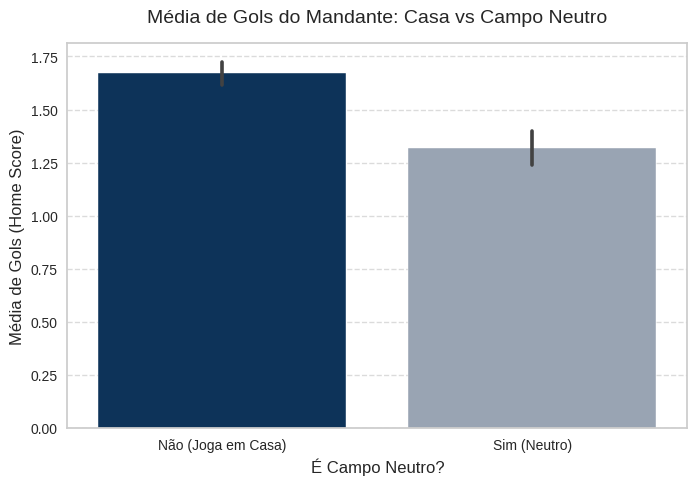

In [55]:
# TESTE DE HIPÓTESES: VALIDANDO O FATOR MANDANTE (HOME ADVANTAGE)
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

df_teste = df.copy()

gols_em_casa = df_teste[df_teste['neutral'] == False]['home_score']

gols_campo_neutro = df_teste[df_teste['neutral'] == True]['home_score']

t_stat, p_valor = stats.ttest_ind(gols_em_casa, gols_campo_neutro, equal_var=False)

print("=== RESULTADO DO TESTE DE HIPÓTESES ===")
print(f"Média de gols (Em Casa):     {gols_em_casa.mean():.2f}")
print(f"Média de gols (Campo Neutro): {gols_campo_neutro.mean():.2f}")
print("-" * 39)
print(f"Estatística t: {t_stat:.4f}")
print(f"Valor-p:       {p_valor:.4e}")
print("-" * 39)

if p_valor < 0.05:
    print("CONCLUSÃO ESTATÍSTICA:")
    print("Rejeitamos a Hipótese Nula (H0)!")
    print("Há evidências matemáticas de que jogar em casa aumenta a média de gols.")
else:
    print("CONCLUSÃO ESTATÍSTICA:")
    print("Falhamos em rejeitar a Hipótese Nula (H0).")
    print("O local da partida não apresenta diferença estatística na média de gols.")

plt.figure(figsize=(8, 5))
sns.barplot(x='neutral', y='home_score', data=df_teste, errorbar='ci', palette=['#003366', '#94a3b8'])
plt.title('Média de Gols do Mandante: Casa vs Campo Neutro', fontsize=14, pad=15)
plt.xlabel('É Campo Neutro?', fontsize=12)
plt.ylabel('Média de Gols (Home Score)', fontsize=12)
plt.xticks([0, 1], ['Não (Joga em Casa)', 'Sim (Neutro)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [56]:
df_teste[df_teste['neutral'] == True].count()


,0
Unnamed: 0,1149
date,1149
home_team,1149
away_team,1149
home_score,1149
away_score,1149
tournament,1149
city,1149
country,1149
neutral,1149


3435
3435
1.6704512372634643 1.0841339155749636
1.6797251696277988 1.275261378577764
=== RESULTADO DO TESTE DE HIPÓTESES ===
Média de gols (Em Casa):     1.67
Média de gols (Campo Neutro): 1.08
---------------------------------------
Estatística t: 16.2939
Valor-p:       1.6186e-58
---------------------------------------
CONCLUSÃO ESTATÍSTICA:
Rejeitamos a Hipótese Nula (H0)!
Há evidências matemáticas de que jogar em casa aumenta a média de gols.


/tmp/ipykernel_571/4216652300.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


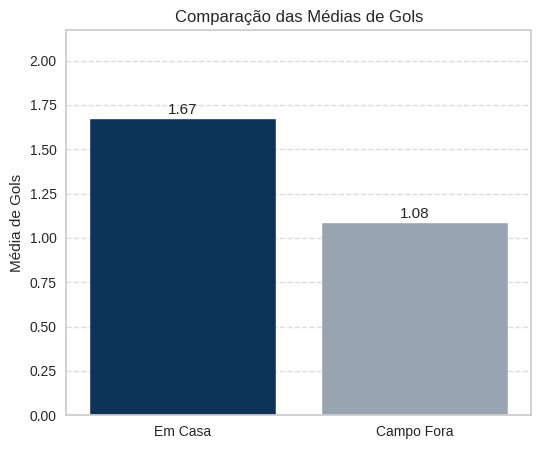

In [57]:
# TESTE DE HIPÓTESES: VALIDANDO O FATOR MANDANTE (HOME ADVANTAGE)
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

df_teste = df.copy()

gols_em_casa = df_teste[df_teste['home_venue_type'] == 'Casa']['home_score']

gols_campo_fora = df_teste[df_teste['away_venue_type'] == 'Fora']['away_score']

t_stat, p_valor = stats.ttest_ind(gols_em_casa, gols_campo_fora, equal_var=False)

print(len(gols_em_casa))
print(len(gols_campo_fora))

print(gols_em_casa.mean(), gols_campo_fora.mean())
print(gols_em_casa.std(), gols_campo_fora.std())

print("=== RESULTADO DO TESTE DE HIPÓTESES ===")
print(f"Média de gols (Em Casa):     {gols_em_casa.mean():.2f}")
print(f"Média de gols (Campo Neutro): {gols_campo_fora.mean():.2f}")
print("-" * 39)
print(f"Estatística t: {t_stat:.4f}")
print(f"Valor-p:       {p_valor:.4e}")
print("-" * 39)

if p_valor < 0.05:
    print("CONCLUSÃO ESTATÍSTICA:")
    print("Rejeitamos a Hipótese Nula (H0)!")
    print("Há evidências matemáticas de que jogar em casa aumenta a média de gols.")
else:
    print("CONCLUSÃO ESTATÍSTICA:")
    print("Falhamos em rejeitar a Hipótese Nula (H0).")
    print("O local da partida não apresenta diferença estatística na média de gols.")

media_casa = gols_em_casa.mean()
media_fora = gols_campo_fora.mean()

plt.figure(figsize=(6,5))

sns.barplot(
    x=['Em Casa', 'Campo Fora'],
    y=[media_casa, media_fora],
    palette=['#003366', '#94a3b8']
)

plt.title('Comparação das Médias de Gols')
plt.ylabel('Média de Gols')
plt.xlabel('')
plt.ylim(0, max(media_casa, media_fora) + 0.5)

# Escreve o valor em cima de cada barra
for i, valor in enumerate([media_casa, media_fora]):
    plt.text(i, valor + 0.03, f'{valor:.2f}', ha='center', fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

=== RESULTADO DO TESTE DE HIPÓTESES ===
Média de gols (Em Casa):     1.67
Média de gols (Campo Neutro): 1.08
---------------------------------------
Estatística t: 13.0379
Valor-p:       3.5329e-38
---------------------------------------
CONCLUSÃO ESTATÍSTICA:
Rejeitamos a Hipótese Nula (H0)!
Há evidências matemáticas de que jogar em casa aumenta a média de gols.


/tmp/ipykernel_571/775010394.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


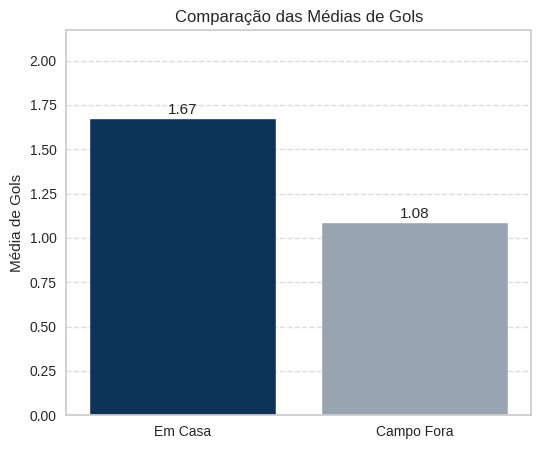

In [58]:
from scipy.stats import ttest_rel

t_stat, p_valor = ttest_rel(df_teste['home_score'], df_teste['away_score'])

print("=== RESULTADO DO TESTE DE HIPÓTESES ===")
print(f"Média de gols (Em Casa):     {gols_em_casa.mean():.2f}")
print(f"Média de gols (Campo Neutro): {gols_campo_fora.mean():.2f}")
print("-" * 39)
print(f"Estatística t: {t_stat:.4f}")
print(f"Valor-p:       {p_valor:.4e}")
print("-" * 39)

if p_valor < 0.05:
    print("CONCLUSÃO ESTATÍSTICA:")
    print("Rejeitamos a Hipótese Nula (H0)!")
    print("Há evidências matemáticas de que jogar em casa aumenta a média de gols.")
else:
    print("CONCLUSÃO ESTATÍSTICA:")
    print("Falhamos em rejeitar a Hipótese Nula (H0).")
    print("O local da partida não apresenta diferença estatística na média de gols.")

media_casa = gols_em_casa.mean()
media_fora = gols_campo_fora.mean()

plt.figure(figsize=(6,5))

sns.barplot(
    x=['Em Casa', 'Campo Fora'],
    y=[media_casa, media_fora],
    palette=['#003366', '#94a3b8']
)

plt.title('Comparação das Médias de Gols')
plt.ylabel('Média de Gols')
plt.xlabel('')
plt.ylim(0, max(media_casa, media_fora) + 0.5)

# Escreve o valor em cima de cada barra
for i, valor in enumerate([media_casa, media_fora]):
    plt.text(i, valor + 0.03, f'{valor:.2f}', ha='center', fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Aprendizado de Maquina Supervisionado (Newton)
Objetivo: Em vez de tentar prever o desfecho final de forma determinística, migramos para uma abordagem de simulação de Monte Carlo. Treinamos um classificador supervisionado para prever o sucesso em confrontos individuais (probabilidade de vitória) e, sobre isso, aplicamos uma estrutura de torneio que simula o caminho de cada seleção até a final, respeitando o chaveamento oficial da Copa 2026.

In [59]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from collections import Counter

df_mc = df.copy()

# Mantém só jogos com vencedor definido
df_mc = df_mc[df_mc["home_score"] != df_mc["away_score"]].copy()

# Alvo binário: 1 se mandante venceu, 0 se perdeu
df_mc["target_home_win"] = (df_mc["home_score"] > df_mc["away_score"]).astype(int)

# Features numéricas baseadas em diferença de forças
feature_cols = [
    "home_Rank", "away_Rank",
    "home_TotalPoints", "away_TotalPoints",
    "home_GER", "away_GER",
    "home_ATQ", "away_ATQ",
    "home_MED", "away_MED",
    "home_DEF", "away_DEF",
    "home_form_pts", "away_form_pts",
    "home_aproveitamento", "away_aproveitamento",
    "home_h2h_pts", "away_h2h_pts",
    "rest_days_diff",
    "neutral"
]

df_model = df_mc[feature_cols + ["target_home_win"]].dropna().copy()

X = df_model[feature_cols]
y = df_model["target_home_win"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

modelo_confronto = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42
)

modelo_confronto.fit(X_train, y_train)

print("Acurácia teste:", modelo_confronto.score(X_test, y_test))

Acurácia teste: 0.7946554149085795


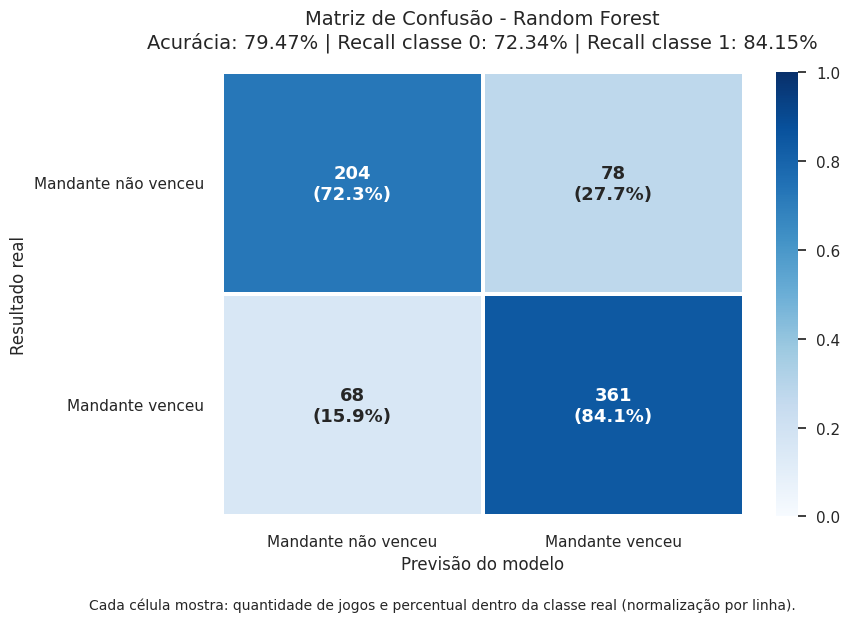

Acurácia: 79.47%

Relatório de Classificação:

                     precision    recall  f1-score   support

Mandante não venceu       0.75      0.72      0.74       282
    Mandante venceu       0.82      0.84      0.83       429

           accuracy                           0.79       711
          macro avg       0.79      0.78      0.78       711
       weighted avg       0.79      0.79      0.79       711



In [60]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Previsões
y_pred = modelo_confronto.predict(X_test)

# Matrizes: absoluta e normalizada por linha
cm_abs = confusion_matrix(y_test, y_pred)
cm_norm = confusion_matrix(y_test, y_pred, normalize='true')

# Métricas principais
acc = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)

recall_classe_0 = report["0"]["recall"]
recall_classe_1 = report["1"]["recall"]
precision_classe_0 = report["0"]["precision"]
precision_classe_1 = report["1"]["precision"]

# Labels
classes = ["Mandante não venceu", "Mandante venceu"]

# Texto de anotação: contagem + %
annot = np.empty_like(cm_abs).astype(str)
for i in range(cm_abs.shape[0]):
    for j in range(cm_abs.shape[1]):
        annot[i, j] = f"{cm_abs[i, j]}\n({cm_norm[i, j]*100:.1f}%)"

# Estilo visual
plt.figure(figsize=(9, 6))
sns.set_theme(style="white")

ax = sns.heatmap(
    cm_norm,
    annot=annot,
    fmt="",
    cmap="Blues",
    cbar=True,
    linewidths=1.5,
    linecolor="white",
    xticklabels=classes,
    yticklabels=classes,
    vmin=0,
    vmax=1,
    annot_kws={"size": 13, "weight": "bold"}
)

# Títulos
plt.title(
    f"Matriz de Confusão - Random Forest\n"
    f"Acurácia: {acc:.2%} | Recall classe 0: {recall_classe_0:.2%} | Recall classe 1: {recall_classe_1:.2%}",
    fontsize=14,
    pad=18
)

plt.xlabel("Previsão do modelo", fontsize=12)
plt.ylabel("Resultado real", fontsize=12)
plt.xticks(rotation=0, fontsize=11)
plt.yticks(rotation=0, fontsize=11)

# Texto auxiliar
plt.figtext(
    0.5, -0.03,
    "Cada célula mostra: quantidade de jogos e percentual dentro da classe real (normalização por linha).",
    ha="center",
    fontsize=10
)

plt.tight_layout()
plt.show()

# Relatório textual no console
print("Acurácia:", f"{acc:.2%}")
print("\nRelatório de Classificação:\n")
print(classification_report(y_test, y_pred, target_names=classes))

In [61]:
y

,target_home_win
1,1
2,1
3,0
4,1
5,0
...,...
4807,1
4809,1
4810,1
4811,1


In [62]:
X

,home_Rank,away_Rank,home_TotalPoints,away_TotalPoints,home_GER,away_GER,home_ATQ,away_ATQ,home_MED,away_MED,home_DEF,away_DEF,home_form_pts,away_form_pts,home_aproveitamento,away_aproveitamento,home_h2h_pts,away_h2h_pts,rest_days_diff,neutral
1,182.0,160.0,936.000000,1005.000000,58.0,60.0,57.0,60.0,58.0,60.0,57.0,59.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
2,19.0,29.0,1536.000000,1484.000000,74.0,75.0,82.0,74.0,74.0,74.0,73.0,76.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
3,44.0,35.0,1430.000000,1468.000000,76.0,74.0,76.0,74.0,74.0,74.0,75.0,73.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
4,53.0,87.0,1406.000000,1280.000000,74.0,68.0,75.0,68.0,75.0,68.0,73.0,67.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
5,55.0,47.0,1392.000000,1416.000000,75.0,69.0,72.0,70.0,77.0,69.0,73.0,66.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4807,34.0,63.0,1532.042117,1401.066156,77.0,72.0,82.0,72.0,75.0,72.0,77.0,71.0,11.0,10.0,59.1,44.4,9.0,3.0,-1.0,False
4809,48.0,70.0,1468.222193,1362.459023,74.0,71.0,74.0,71.0,74.0,71.0,73.0,70.0,8.0,8.0,50.9,60.3,0.0,0.0,79.0,True
4810,42.0,34.0,1487.129128,1532.042117,78.0,77.0,86.0,82.0,79.0,75.0,75.0,77.0,4.0,13.0,58.3,49.5,3.0,3.0,0.0,False
4811,58.0,76.0,1436.943164,1330.521224,73.0,66.0,73.0,59.0,73.0,66.0,72.0,66.0,11.0,9.0,58.3,11.1,0.0,0.0,128.0,True


In [63]:
# Pega o registro mais recente de cada time aparecendo como mandante
home_latest = (
    df.sort_values("date")
      .groupby("home_team")
      .tail(1)[[
          "home_team", "home_Rank", "home_TotalPoints",
          "home_GER", "home_ATQ", "home_MED", "home_DEF",
          "home_form_pts", "home_aproveitamento", "home_h2h_pts"
      ]]
      .copy()
)

home_latest.columns = [
    "team", "Rank", "TotalPoints",
    "GER", "ATQ", "MED", "DEF",
    "form_pts", "aproveitamento", "h2h_pts"
]

away_latest = (
    df.sort_values("date")
      .groupby("away_team")
      .tail(1)[[
          "away_team", "away_Rank", "away_TotalPoints",
          "away_GER", "away_ATQ", "away_MED", "away_DEF",
          "away_form_pts", "away_aproveitamento", "away_h2h_pts"
      ]]
      .copy()
)

away_latest.columns = [
    "team", "Rank", "TotalPoints",
    "GER", "ATQ", "MED", "DEF",
    "form_pts", "aproveitamento", "h2h_pts"
]

# Junta e prioriza a última aparição disponível
team_stats = pd.concat([home_latest, away_latest], ignore_index=True)
team_stats = team_stats.sort_values("team").drop_duplicates("team", keep="last")
team_stats = team_stats.set_index("team")

team_stats.head()

,Rank,TotalPoints,GER,ATQ,MED,DEF,form_pts,aproveitamento,h2h_pts
team,,,,,,,,,
Afghanistan,161.0,998.876637,60.0,59.0,60.0,59.0,4.0,25.0,0.0
Albania,61.0,1401.339277,72.0,72.0,72.0,71.0,11.0,54.3,0.0
Algeria,34.0,1517.679369,75.0,76.0,75.0,74.0,13.0,65.0,4.0
American Samoa,187.0,890.970000,57.0,56.0,56.0,56.0,0.0,0.0,0.0
Andorra,172.0,955.102601,59.0,58.0,59.0,58.0,1.0,19.0,1.0


In [64]:
def montar_features_confronto(time_a, time_b, neutral=True):
    a = team_stats.loc[time_a]
    b = team_stats.loc[time_b]

    linha = pd.DataFrame([{
        "home_Rank": a["Rank"],
        "away_Rank": b["Rank"],
        "home_TotalPoints": a["TotalPoints"],
        "away_TotalPoints": b["TotalPoints"],
        "home_GER": a["GER"],
        "away_GER": b["GER"],
        "home_ATQ": a["ATQ"],
        "away_ATQ": b["ATQ"],
        "home_MED": a["MED"],
        "away_MED": b["MED"],
        "home_DEF": a["DEF"],
        "away_DEF": b["DEF"],
        "home_form_pts": a["form_pts"],
        "away_form_pts": b["form_pts"],
        "home_aproveitamento": a["aproveitamento"],
        "away_aproveitamento": b["aproveitamento"],
        "home_h2h_pts": 0,
        "away_h2h_pts": 0,
        "rest_days_diff": 0,
        "neutral": neutral
    }])

    return linha

def prob_vitoria(time_a, time_b):
    X_match = montar_features_confronto(time_a, time_b, neutral=True)
    p = modelo_confronto.predict_proba(X_match)[0][1]
    return p

In [65]:
grupos_2026 = {
    "A": ["Mexico", "South Africa", "Korea Republic", "Czech Republic"],
    "B": ["Switzerland", "Canada", "Bosnia and Herzegovina", "Qatar"],
    "C": ["Brazil", "Morocco", "Scotland", "Haiti"],
    "D": ["USA", "Australia", "Paraguay", "Turkey"],
    "E": ["Germany", "Côte d'Ivoire", "Ecuador", "Curaçao"],
    "F": ["Netherlands", "Japan", "Sweden", "Tunisia"],
    "G": ["Belgium", "Egypt", "IR Iran", "New Zealand"],
    "H": ["Spain", "Cabo Verde", "Uruguay", "Saudi Arabia"],
    "I": ["France", "Norway", "Senegal", "Iraq"],
    "J": ["Argentina", "Austria", "Algeria", "Jordan"],
    "K": ["Colombia", "Portugal", "Congo DR", "Uzbekistan"],
    "L": ["England", "Croatia", "Ghana", "Panama"]
}

def validar_grupos(grupos):
    selecoes = sorted({time for grupo in grupos.values() for time in grupo})
    faltando = [time for time in selecoes if time not in team_stats.index]

    if faltando:
        raise ValueError(f"As seguintes seleções não estão em team_stats: {faltando}")

validar_grupos(grupos_2026)

selecoes_2026 = sorted({time for grupo in grupos_2026.values() for time in grupo})

def montar_features_array(time_a, time_b, neutral=True):
    a = team_stats.loc[time_a]
    b = team_stats.loc[time_b]

    return [
        a["Rank"], b["Rank"],
        a["TotalPoints"], b["TotalPoints"],
        a["GER"], b["GER"],
        a["ATQ"], b["ATQ"],
        a["MED"], b["MED"],
        a["DEF"], b["DEF"],
        a["form_pts"], b["form_pts"],
        a["aproveitamento"], b["aproveitamento"],
        0, 0,
        0,
        int(neutral)
    ]

def precomputar_probabilidades(selecoes):
    pares = []
    features = []

    for i in range(len(selecoes)):
        for j in range(len(selecoes)):
            if i != j:
                time_a = selecoes[i]
                time_b = selecoes[j]
                pares.append((time_a, time_b))
                features.append(montar_features_array(time_a, time_b, neutral=True))

    X_all = pd.DataFrame(features, columns=feature_cols)
    probs = modelo_confronto.predict_proba(X_all)[:, 1]

    prob_cache = {}
    for (time_a, time_b), p in zip(pares, probs):
        prob_cache[(time_a, time_b)] = p

    return prob_cache

prob_cache = precomputar_probabilidades(selecoes_2026)

def prob_vitoria(time_a, time_b):
    return prob_cache[(time_a, time_b)]

def simular_partida(time_a, time_b):
    p_a = prob_cache[(time_a, time_b)]
    aleatorio = np.random.rand()
    vencedor = time_a if aleatorio < p_a else time_b
    return vencedor

def gerar_jogos_grupo(times):
    jogos = []
    for i in range(len(times)):
        for j in range(i + 1, len(times)):
            jogos.append((times[i], times[j]))
    return jogos

def simular_grupo_rapido(nome_grupo, times):
    tabela = {
        time: {"Grupo": nome_grupo, "Seleção": time, "Pontos": 0, "Saldo": 0, "Vitórias": 0}
        for time in times
    }

    jogos = gerar_jogos_grupo(times)

    for time_a, time_b in jogos:
        vencedor = simular_partida(time_a, time_b)
        perdedor = time_b if vencedor == time_a else time_a

        tabela[vencedor]["Pontos"] += 3
        tabela[vencedor]["Vitórias"] += 1
        tabela[vencedor]["Saldo"] += 1
        tabela[perdedor]["Saldo"] -= 1

    ranking = sorted(
        tabela.values(),
        key=lambda x: (x["Pontos"], x["Saldo"], x["Vitórias"]),
        reverse=True
    )

    for i, item in enumerate(ranking):
        item["Posição"] = i + 1

    return ranking

def simular_fase_de_grupos_rapida(grupos):
    resumo_grupos = []
    primeiros = []
    segundos = []
    terceiros = []

    for grupo, times in grupos.items():
        ranking = simular_grupo_rapido(grupo, times)
        resumo_grupos.extend(ranking)

        primeiros.append(ranking[0]["Seleção"])
        segundos.append(ranking[1]["Seleção"])
        terceiros.append(ranking[2])

    melhores_terceiros = sorted(
        terceiros,
        key=lambda x: (x["Pontos"], x["Saldo"], x["Vitórias"]),
        reverse=True
    )[:8]

    return {
        "resumo_grupos": pd.DataFrame(resumo_grupos).sort_values(["Grupo", "Posição"]).reset_index(drop=True),
        "primeiros": primeiros,
        "segundos": segundos,
        "melhores_terceiros": [x["Seleção"] for x in melhores_terceiros],
        "df_melhores_terceiros": pd.DataFrame(melhores_terceiros).reset_index(drop=True)
    }


def montar_round_of_32(primeiros, segundos, melhores_terceiros):
    jogos = []

    for i in range(8):
        jogos.append((primeiros[i], melhores_terceiros[i]))

    for i in range(8, 12):
        jogos.append((primeiros[i], segundos[i - 8]))

    jogos.extend([
        (segundos[4], segundos[5]),
        (segundos[6], segundos[7]),
        (segundos[8], segundos[9]),
        (segundos[10], segundos[11]),
    ])

    return jogos

def simular_rodada_rapida(lista_confrontos):
    vencedores = []
    for time_a, time_b in lista_confrontos:
        vencedores.append(simular_partida(time_a, time_b))
    return vencedores

def montar_proxima_rodada(vencedores):
    return [(vencedores[i], vencedores[i + 1]) for i in range(0, len(vencedores), 2)]

def simular_torneio_com_grupos_rapido():
    fase_grupos = simular_fase_de_grupos_rapida(grupos_2026)

    round_32 = montar_round_of_32(
        fase_grupos["primeiros"],
        fase_grupos["segundos"],
        fase_grupos["melhores_terceiros"]
    )

    vencedores_32 = simular_rodada_rapida(round_32)
    oitavas = montar_proxima_rodada(vencedores_32)

    vencedores_oitavas = simular_rodada_rapida(oitavas)
    quartas = montar_proxima_rodada(vencedores_oitavas)

    vencedores_quartas = simular_rodada_rapida(quartas)
    semis = montar_proxima_rodada(vencedores_quartas)

    vencedores_semis = simular_rodada_rapida(semis)
    final = montar_proxima_rodada(vencedores_semis)

    vencedores_final = simular_rodada_rapida(final)

    campeao = vencedores_final[0]
    vice = final[0][1] if campeao == final[0][0] else final[0][0]

    return {
        "campeao": campeao,
        "vice": vice
    }

teste_grupos = simular_fase_de_grupos_rapida(grupos_2026)
display(teste_grupos["resumo_grupos"])
display(teste_grupos["df_melhores_terceiros"])

teste_torneio = simular_torneio_com_grupos_rapido()
print("Campeão em uma simulação:", teste_torneio["campeao"])

,Grupo,Seleção,Pontos,Saldo,Vitórias,Posição
0,A,Mexico,9,3,3,1
1,A,Korea Republic,6,1,2,2
2,A,Czech Republic,3,-1,1,3
3,A,South Africa,0,-3,0,4
4,B,Switzerland,9,3,3,1
5,B,Qatar,6,1,2,2
6,B,Canada,3,-1,1,3
7,B,Bosnia and Herzegovina,0,-3,0,4
8,C,Brazil,9,3,3,1
9,C,Morocco,6,1,2,2


,Grupo,Seleção,Pontos,Saldo,Vitórias,Posição
0,D,Turkey,6,1,2,3
1,A,Czech Republic,3,-1,1,3
2,B,Canada,3,-1,1,3
3,C,Scotland,3,-1,1,3
4,E,Côte d'Ivoire,3,-1,1,3
5,F,Japan,3,-1,1,3
6,G,Egypt,3,-1,1,3
7,H,Saudi Arabia,3,-1,1,3


Campeão em uma simulação: Netherlands


In [66]:
n_simulacoes = 1000
campeoes = []
vices = []

for _ in range(n_simulacoes):
    resultado = simular_torneio_com_grupos_rapido()
    campeoes.append(resultado["campeao"])
    vices.append(resultado["vice"])

ranking_campeoes = pd.Series(campeoes).value_counts().reset_index()
ranking_campeoes.columns = ["Seleção", "Títulos_simulados"]
ranking_campeoes["Prob_campeao"] = ranking_campeoes["Títulos_simulados"] / n_simulacoes

ranking_vices = pd.Series(vices).value_counts().reset_index()
ranking_vices.columns = ["Seleção", "Vices_simulados"]

ranking_final = ranking_campeoes.merge(ranking_vices, on="Seleção", how="left").fillna(0)
ranking_final = ranking_final.sort_values(
    by=["Títulos_simulados", "Vices_simulados"],
    ascending=False
).reset_index(drop=True)

display(ranking_final)

,Seleção,Títulos_simulados,Prob_campeao,Vices_simulados
0,England,154,0.154,77
1,Spain,133,0.133,120
2,France,110,0.110,48
3,Argentina,104,0.104,62
4,Netherlands,84,0.084,71
5,Portugal,80,0.080,71
6,Brazil,78,0.078,99
7,Germany,66,0.066,62
8,Belgium,44,0.044,63
9,Switzerland,23,0.023,53


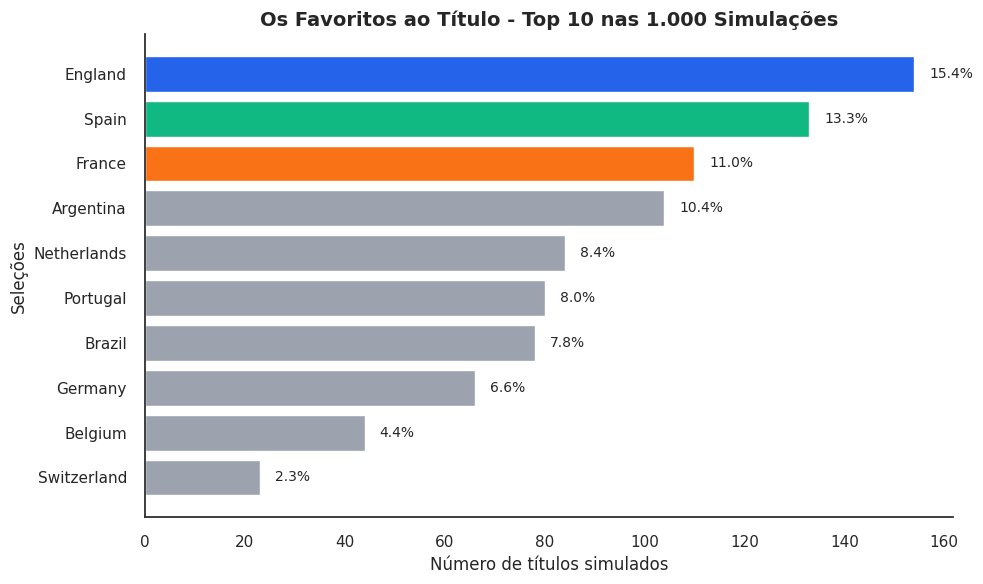

In [67]:
# Top 10 seleções com mais títulos simulados
top10 = ranking_final.sort_values("Títulos_simulados", ascending=False).head(10).copy()

# Ordena para o gráfico horizontal ficar do menor para o maior
top10 = top10.sort_values("Títulos_simulados", ascending=True)

# Paleta: top 3 destacados
cores = []
ranking_desc = ranking_final.sort_values("Títulos_simulados", ascending=False)["Seleção"].tolist()

for selecao in top10["Seleção"]:
    pos = ranking_desc.index(selecao)
    if pos == 0:
        cores.append("#2563eb")
    elif pos == 1:
        cores.append("#10b981")
    elif pos == 2:
        cores.append("#f97316")
    else:
        cores.append("#9ca3af")

plt.figure(figsize=(10, 6))
bars = plt.barh(top10["Seleção"], top10["Títulos_simulados"], color=cores)

plt.title("Os Favoritos ao Título - Top 10 nas 1.000 Simulações", fontsize=14, weight="bold")
plt.xlabel("Número de títulos simulados")
plt.ylabel("Seleções")

# Adiciona rótulo com a probabilidade
for i, (titulos, prob) in enumerate(zip(top10["Títulos_simulados"], top10["Prob_campeao"])):
    plt.text(
        titulos + 3,
        i,
        f"{prob:.1%}",
        va="center",
        fontsize=10
    )

sns.despine()
plt.tight_layout()
plt.show()

# Aprendizado de Máquina Não Supervisionado (Davi)

Objetivo: Responder a pergunta "Quais os principais padrões identificados nas seleções que jogaram na Copa do Mundo em 2022?". Para tal, será utilizado o algoritmo de agrupamento k means, principalmente pela quantidade reduzida de dados e pela distância que esses dados possuem entre si.

# Importações
`KMeans` e `KElbowVisualizer` serão utilizados para importar o algoritmo k means e o algoritmo de "método do cotovelo", respectivamente.
`StandardScaler` será utilizado para normalizar os dados numéricos que serão utilizados.
Por fim, a biblioteca `matplotlib` será utilizada para esboçar gráficos que representem os resultados obtidos.

In [68]:
!pip install yellowbrick

In [69]:
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Análise e Filtragem de dados
A ideia é selecionar as seleções que participaram da Copa do Mundo em 2022, removendo as colunas que não auxiliam na análise geral das seleções individualmente, como nos casos da data, cidade e país.

In [70]:
df.tournament.unique()

array(['CONCACAF Nations League qualification', 'UEFA Nations League',
       'African Cup of Nations qualification', 'AFC Asian Cup',
       'UEFA Euro qualification', 'FIFA World Cup qualification',
       'Copa América', 'Gold Cup', 'African Cup of Nations',
       'CONCACAF Nations League', 'UEFA Euro', 'Gold Cup qualification',
       'AFC Asian Cup qualification', 'FIFA World Cup',
       'Oceania Nations Cup qualification', 'Copa América qualification',
       'Oceania Nations Cup'], dtype=object)

In [71]:
worls_cup_df = df[(df.tournament == 'FIFA World Cup') & (df.date.dt.year == 2022)]
worls_cup_df

,Unnamed: 0,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral,...,away_Rank,away_TotalPoints,home_GER,home_ATQ,home_MED,home_DEF,away_GER,away_ATQ,away_MED,away_DEF
2527,2527,2022-11-20,Qatar,Ecuador,0.0,2.0,FIFA World Cup,Al Khor,Qatar,False,...,44.0,1464.39,69.0,71.0,70.0,68.0,75.0,75.0,75.0,75.0
2528,2528,2022-11-21,USA,Wales,1.0,1.0,FIFA World Cup,Al Rayyan,Qatar,True,...,19.0,1569.82,75.0,76.0,76.0,74.0,74.0,75.0,74.0,73.0
2529,2529,2022-11-21,Senegal,Netherlands,0.0,2.0,FIFA World Cup,Doha,Qatar,True,...,8.0,1694.51,78.0,79.0,76.0,77.0,82.0,83.0,81.0,82.0
2530,2530,2022-11-21,England,IR Iran,6.0,2.0,FIFA World Cup,Al Rayyan,Qatar,True,...,20.0,1564.61,83.0,86.0,83.0,83.0,73.0,81.0,73.0,72.0
2531,2531,2022-11-22,Mexico,Poland,0.0,0.0,FIFA World Cup,Doha,Qatar,True,...,26.0,1548.59,78.0,79.0,77.0,76.0,78.0,80.0,76.0,74.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2586,2586,2022-12-10,Morocco,Portugal,1.0,0.0,FIFA World Cup,Doha,Qatar,True,...,9.0,1676.56,77.0,78.0,72.0,79.0,83.0,84.0,83.0,84.0
2587,2587,2022-12-13,Argentina,Croatia,3.0,0.0,FIFA World Cup,Lusail,Qatar,True,...,12.0,1645.64,83.0,86.0,82.0,81.0,80.0,80.0,82.0,78.0
2588,2588,2022-12-14,France,Morocco,2.0,0.0,FIFA World Cup,Al Khor,Qatar,True,...,22.0,1563.50,84.0,88.0,82.0,83.0,77.0,78.0,72.0,79.0
2589,2589,2022-12-17,Croatia,Morocco,2.0,1.0,FIFA World Cup,Al Rayyan,Qatar,True,...,22.0,1563.50,80.0,80.0,82.0,78.0,77.0,78.0,72.0,79.0


In [72]:
worls_cup_df['Unnamed: 0']

,Unnamed: 0
2527,2527
2528,2528
2529,2529
2530,2530
2531,2531
...,...
2586,2586
2587,2587
2588,2588
2589,2589


In [73]:
display(worls_cup_df.columns)

Index(['Unnamed: 0', 'date', 'home_team', 'away_team', 'home_score',
       'away_score', 'tournament', 'city', 'country', 'neutral', 'winner',
       'first_shooter', 'home_form_pts', 'away_form_pts', 'home_venue_type',
       'home_aproveitamento', 'away_venue_type', 'away_aproveitamento',
       'rest_days_diff', 'home_h2h_pts', 'away_h2h_pts', 'home_form_gd',
       'away_form_gd', 'home_pen_win_rate', 'away_pen_win_rate',
       'tournament_weight', 'home_Rank', 'home_TotalPoints', 'away_Rank',
       'away_TotalPoints', 'home_GER', 'home_ATQ', 'home_MED', 'home_DEF',
       'away_GER', 'away_ATQ', 'away_MED', 'away_DEF'],
      dtype='object')

In [74]:
clean_df = worls_cup_df.drop(columns=['Unnamed: 0', 'date', 'tournament', 'city', 'country', 'neutral', 'winner',
       'first_shooter', 'home_venue_type', 'away_venue_type',
       'rest_days_diff', 'home_h2h_pts', 'away_h2h_pts',
       'tournament_weight'])
clean_df.columns

Index(['home_team', 'away_team', 'home_score', 'away_score', 'home_form_pts',
       'away_form_pts', 'home_aproveitamento', 'away_aproveitamento',
       'home_form_gd', 'away_form_gd', 'home_pen_win_rate',
       'away_pen_win_rate', 'home_Rank', 'home_TotalPoints', 'away_Rank',
       'away_TotalPoints', 'home_GER', 'home_ATQ', 'home_MED', 'home_DEF',
       'away_GER', 'away_ATQ', 'away_MED', 'away_DEF'],
      dtype='object')

Nessa etapa, criamos um dataframe organizando agrupando por seleções.

In [75]:
cleaned_worls_cup_df = pd.concat([
    clean_df[['home_team', 'home_score', 'home_form_pts', 'home_aproveitamento',
              'home_form_gd', 'home_pen_win_rate', 'home_Rank', 'home_TotalPoints',
              'home_GER', 'home_ATQ', 'home_MED', 'home_DEF']].rename(columns={
                  'home_team' : 'team',
                  'home_score' : 'gols',
                  'home_form_pts' : 'form_points',
                  'home_aproveitamento' : 'aproveitamento',
                  'home_form_gd' : 'form_gd',
                  'home_pen_win_rate' : 'pen_win_rate',
                  'home_Rank' : 'rank',
                  'home_TotalPoints' : 'total_points',
                  'home_GER' : 'GER_atribute',
                  'home_ATQ' : 'ATQ_atribute',
                  'home_MED' : 'MED_atribut',
                  'home_DEF' : 'DEF_atribute'
                  }),
    clean_df[['away_team', 'away_score', 'away_form_pts', 'away_aproveitamento',
              'away_form_gd', 'away_pen_win_rate', 'away_Rank', 'away_TotalPoints',
              'away_GER', 'away_ATQ', 'away_MED', 'away_DEF']].rename(columns={
                  'away_team' : 'team',
                  'away_score' : 'gols',
                  'away_form_pts' : 'form_points',
                  'away_aproveitamento' : 'aproveitamento',
                  'away_form_gd' : 'form_gd',
                  'away_pen_win_rate' : 'pen_win_rate',
                  'away_Rank' : 'rank',
                  'away_TotalPoints' : 'total_points',
                  'away_GER' : 'GER_atribute',
                  'away_ATQ' : 'ATQ_atribute',
                  'away_MED' : 'MED_atribut',
                  'away_DEF' : 'DEF_atribute'
                  })
    ], ignore_index=True)
cleaned_worls_cup_df

,team,gols,form_points,aproveitamento,form_gd,pen_win_rate,rank,total_points,GER_atribute,ATQ_atribute,MED_atribut,DEF_atribute
0,Qatar,0.0,10.0,88.9,1.2,0.5,50.0,1439.89,69.0,71.0,70.0,68.0
1,USA,1.0,8.0,100.0,1.4,0.5,16.0,1627.48,75.0,76.0,76.0,74.0
2,Senegal,0.0,10.0,73.3,0.6,1.0,18.0,1584.38,78.0,79.0,76.0,77.0
3,England,6.0,3.0,44.4,-1.0,0.5,5.0,1728.47,83.0,86.0,83.0,83.0
4,Mexico,0.0,11.0,81.8,1.2,1.0,13.0,1644.89,78.0,79.0,77.0,76.0
...,...,...,...,...,...,...,...,...,...,...,...,...
123,Portugal,0.0,9.0,61.9,1.2,0.5,9.0,1676.56,83.0,84.0,83.0,84.0
124,Croatia,0.0,7.0,38.1,0.6,1.0,12.0,1645.64,80.0,80.0,82.0,78.0
125,Morocco,0.0,11.0,75.6,0.8,0.5,22.0,1563.50,77.0,78.0,72.0,79.0
126,Morocco,1.0,10.0,70.8,0.4,0.5,22.0,1563.50,77.0,78.0,72.0,79.0


In [76]:
cleaned_worls_cup_mean_df = cleaned_worls_cup_df.groupby('team').mean()
cleaned_worls_cup_mean_df.fillna(0, inplace=True)
cleaned_worls_cup_mean_df

,gols,form_points,aproveitamento,form_gd,pen_win_rate,rank,total_points,GER_atribute,ATQ_atribute,MED_atribut,DEF_atribute
team,,,,,,,,,,,
Argentina,2.142857,10.571429,70.942857,1.028571,1.000000,3.0,1773.88,83.000000,86.000000,82.000000,81.00
Australia,1.000000,6.500000,72.225000,-0.450000,1.000000,38.0,1488.72,71.000000,75.000000,71.000000,70.00
Belgium,0.333333,9.666667,61.266667,0.533333,0.500000,2.0,1816.71,82.000000,83.000000,82.000000,79.00
Brazil,1.600000,12.600000,68.340000,2.400000,1.000000,1.0,1841.30,80.000000,81.000000,80.000000,80.00
Cameroon,1.333333,7.333333,60.200000,0.066667,0.500000,43.0,1471.44,75.000000,75.000000,75.000000,72.00
Canada,0.666667,5.000000,75.200000,0.533333,0.500000,41.0,1475.00,73.000000,74.000000,74.000000,70.00
Costa Rica,1.000000,10.000000,61.133333,-0.333333,0.000000,31.0,1503.59,74.000000,73.000000,73.000000,74.00
Croatia,1.142857,10.285714,32.985714,0.885714,0.714286,12.0,1645.64,80.000000,80.000000,82.000000,78.00
Denmark,0.333333,7.666667,78.700000,0.466667,0.500000,10.0,1666.57,78.000000,76.000000,82.000000,78.00


In [77]:
team_df_treino_cluster = cleaned_worls_cup_mean_df.index
stats_dataset = cleaned_worls_cup_mean_df.copy()
stats_dataset

,gols,form_points,aproveitamento,form_gd,pen_win_rate,rank,total_points,GER_atribute,ATQ_atribute,MED_atribut,DEF_atribute
team,,,,,,,,,,,
Argentina,2.142857,10.571429,70.942857,1.028571,1.000000,3.0,1773.88,83.000000,86.000000,82.000000,81.00
Australia,1.000000,6.500000,72.225000,-0.450000,1.000000,38.0,1488.72,71.000000,75.000000,71.000000,70.00
Belgium,0.333333,9.666667,61.266667,0.533333,0.500000,2.0,1816.71,82.000000,83.000000,82.000000,79.00
Brazil,1.600000,12.600000,68.340000,2.400000,1.000000,1.0,1841.30,80.000000,81.000000,80.000000,80.00
Cameroon,1.333333,7.333333,60.200000,0.066667,0.500000,43.0,1471.44,75.000000,75.000000,75.000000,72.00
Canada,0.666667,5.000000,75.200000,0.533333,0.500000,41.0,1475.00,73.000000,74.000000,74.000000,70.00
Costa Rica,1.000000,10.000000,61.133333,-0.333333,0.000000,31.0,1503.59,74.000000,73.000000,73.000000,74.00
Croatia,1.142857,10.285714,32.985714,0.885714,0.714286,12.0,1645.64,80.000000,80.000000,82.000000,78.00
Denmark,0.333333,7.666667,78.700000,0.466667,0.500000,10.0,1666.57,78.000000,76.000000,82.000000,78.00


In [78]:
stats_dataset['rank'] = stats_dataset['rank'].max() - stats_dataset['rank']
stats_dataset

,gols,form_points,aproveitamento,form_gd,pen_win_rate,rank,total_points,GER_atribute,ATQ_atribute,MED_atribut,DEF_atribute
team,,,,,,,,,,,
Argentina,2.142857,10.571429,70.942857,1.028571,1.000000,58.0,1773.88,83.000000,86.000000,82.000000,81.00
Australia,1.000000,6.500000,72.225000,-0.450000,1.000000,23.0,1488.72,71.000000,75.000000,71.000000,70.00
Belgium,0.333333,9.666667,61.266667,0.533333,0.500000,59.0,1816.71,82.000000,83.000000,82.000000,79.00
Brazil,1.600000,12.600000,68.340000,2.400000,1.000000,60.0,1841.30,80.000000,81.000000,80.000000,80.00
Cameroon,1.333333,7.333333,60.200000,0.066667,0.500000,18.0,1471.44,75.000000,75.000000,75.000000,72.00
Canada,0.666667,5.000000,75.200000,0.533333,0.500000,20.0,1475.00,73.000000,74.000000,74.000000,70.00
Costa Rica,1.000000,10.000000,61.133333,-0.333333,0.000000,30.0,1503.59,74.000000,73.000000,73.000000,74.00
Croatia,1.142857,10.285714,32.985714,0.885714,0.714286,49.0,1645.64,80.000000,80.000000,82.000000,78.00
Denmark,0.333333,7.666667,78.700000,0.466667,0.500000,51.0,1666.57,78.000000,76.000000,82.000000,78.00


In [79]:
scaler = StandardScaler()

Neste ponto, além de aplicar a normalização, foram atreladas a duas variáveis a média dos valores das seleções e seus desvios padrões.

In [80]:
number_data = stats_dataset.select_dtypes(include=['number'])

display(number_data)

normalized_data = scaler.fit_transform(number_data)
general_team_mean = number_data.mean()
general_team_std = number_data.std()
normalized_data

,gols,form_points,aproveitamento,form_gd,pen_win_rate,rank,total_points,GER_atribute,ATQ_atribute,MED_atribut,DEF_atribute
team,,,,,,,,,,,
Argentina,2.142857,10.571429,70.942857,1.028571,1.000000,58.0,1773.88,83.000000,86.000000,82.000000,81.00
Australia,1.000000,6.500000,72.225000,-0.450000,1.000000,23.0,1488.72,71.000000,75.000000,71.000000,70.00
Belgium,0.333333,9.666667,61.266667,0.533333,0.500000,59.0,1816.71,82.000000,83.000000,82.000000,79.00
Brazil,1.600000,12.600000,68.340000,2.400000,1.000000,60.0,1841.30,80.000000,81.000000,80.000000,80.00
Cameroon,1.333333,7.333333,60.200000,0.066667,0.500000,18.0,1471.44,75.000000,75.000000,75.000000,72.00
Canada,0.666667,5.000000,75.200000,0.533333,0.500000,20.0,1475.00,73.000000,74.000000,74.000000,70.00
Costa Rica,1.000000,10.000000,61.133333,-0.333333,0.000000,30.0,1503.59,74.000000,73.000000,73.000000,74.00
Croatia,1.142857,10.285714,32.985714,0.885714,0.714286,49.0,1645.64,80.000000,80.000000,82.000000,78.00
Denmark,0.333333,7.666667,78.700000,0.466667,0.500000,51.0,1666.57,78.000000,76.000000,82.000000,78.00


array([[ 1.37492438,  0.72666657,  0.68239636,  0.70098167,  1.6328274 ,
         1.19400544,  1.54146146,  1.25734941,  1.70959584,  1.03443691,
         1.04559064],
       [-0.37144447, -0.90866943,  0.75105707, -1.63829215,  1.6328274 ,
        -1.03109621, -0.97815678, -1.51942849, -0.80447068, -1.56643303,
        -1.47960939],
       [-1.39015963,  0.36325857,  0.16422152, -0.08254322, -0.02713746,
         1.25757977,  1.919899  ,  1.02595125,  1.02394134,  1.03443691,
         0.58646336],
       [ 0.54539918,  1.54146556,  0.54300936,  2.87074289,  1.6328274 ,
         1.3211541 ,  2.13717145,  0.56315494,  0.56683833,  0.56155147,
         0.816027  ],
       [ 0.13791311, -0.57395153,  0.10709988, -0.82086474, -0.02713746,
        -1.34896787, -1.13083949, -0.59383585, -0.80447068, -0.62066215,
        -1.02048211],
       [-0.88080205, -1.51116163,  0.91037288, -0.08254322, -0.02713746,
        -1.22181921, -1.09938403, -1.05663217, -1.03302218, -0.85710487,
        -1.479

# Algoritmo
A partir daqui, tendo os dados já organizados e filtrados, daremos início ao uso dos algoritmos de elbow e k means, respectivamente.

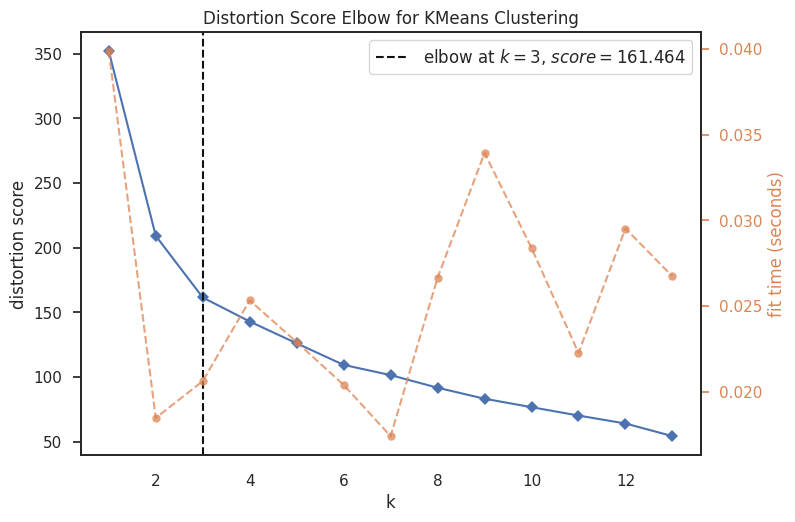

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [81]:
k_means_elbow = KMeans(random_state=42, n_init=10)
k_elbow = KElbowVisualizer(k_means_elbow, k=(1, 14))

k_elbow.fit(normalized_data)
k_elbow.show()

In [82]:
k_means = KMeans(n_clusters=k_elbow.elbow_value_, random_state=42, n_init=10)
k_means_pred = k_means.fit_predict(normalized_data)

In [83]:
cleaned_worls_cup_mean_df['cluster_result'] = k_means_pred
cleaned_worls_cup_mean_df

,gols,form_points,aproveitamento,form_gd,pen_win_rate,rank,total_points,GER_atribute,ATQ_atribute,MED_atribut,DEF_atribute,cluster_result
team,,,,,,,,,,,,
Argentina,2.142857,10.571429,70.942857,1.028571,1.000000,3.0,1773.88,83.000000,86.000000,82.000000,81.00,2
Australia,1.000000,6.500000,72.225000,-0.450000,1.000000,38.0,1488.72,71.000000,75.000000,71.000000,70.00,1
Belgium,0.333333,9.666667,61.266667,0.533333,0.500000,2.0,1816.71,82.000000,83.000000,82.000000,79.00,2
Brazil,1.600000,12.600000,68.340000,2.400000,1.000000,1.0,1841.30,80.000000,81.000000,80.000000,80.00,2
Cameroon,1.333333,7.333333,60.200000,0.066667,0.500000,43.0,1471.44,75.000000,75.000000,75.000000,72.00,1
Canada,0.666667,5.000000,75.200000,0.533333,0.500000,41.0,1475.00,73.000000,74.000000,74.000000,70.00,1
Costa Rica,1.000000,10.000000,61.133333,-0.333333,0.000000,31.0,1503.59,74.000000,73.000000,73.000000,74.00,1
Croatia,1.142857,10.285714,32.985714,0.885714,0.714286,12.0,1645.64,80.000000,80.000000,82.000000,78.00,0
Denmark,0.333333,7.666667,78.700000,0.466667,0.500000,10.0,1666.57,78.000000,76.000000,82.000000,78.00,0


# Análise de Resultados

In [84]:
for cluster in sorted(cleaned_worls_cup_mean_df.cluster_result.unique()):

    dados = cleaned_worls_cup_mean_df[
        cleaned_worls_cup_mean_df.cluster_result == cluster
    ]

    media = dados.drop(columns='cluster_result').mean()
    desvio = dados.drop(columns='cluster_result').std()

    percentual = (media-general_team_mean)*100/general_team_mean

    resultado = pd.concat({
        'Média Geral':general_team_mean,
        'DP Geral':general_team_std,
        f'Média Cluster {cluster}':media,
        f'DP Cluster {cluster}':desvio,
        'Diferença %':percentual
    },axis=1)

    display(resultado)

,Média Geral,DP Geral,Média Cluster 0,DP Cluster 0,Diferença %
gols,1.243080,0.664890,1.034722,0.376717,-16.761437
form_points,8.762277,2.529496,10.124008,1.359177,15.540837
aproveitamento,58.200060,18.972398,61.453671,21.943392,5.590391
form_gd,0.585506,0.642178,0.785913,0.330479,34.227960
pen_win_rate,0.508174,0.306031,0.480131,0.323434,-5.518415
rank,39.218750,15.981308,17.750000,5.378831,-54.741036
total_points,1599.423750,114.986805,1602.096667,45.395322,0.167117
GER_atribute,77.566295,4.390705,77.416667,2.108784,-0.192903
ATQ_atribute,78.519866,4.445392,78.488095,2.019808,-0.040462
MED_atribut,77.625000,4.297028,77.488095,3.388542,-0.176367


,Média Geral,DP Geral,Média Cluster 1,DP Cluster 1,Diferença %
gols,1.243080,0.664890,0.886364,0.450729,-28.696192
form_points,8.762277,2.529496,6.689394,2.308827,-23.656898
aproveitamento,58.200060,18.972398,50.657576,21.391107,-12.959581
form_gd,0.585506,0.642178,0.028788,0.512407,-95.083247
pen_win_rate,0.508174,0.306031,0.500000,0.316228,-1.608525
rank,39.218750,15.981308,39.454545,12.274882,0.601231
total_points,1599.423750,114.986805,1481.796364,50.428155,-7.354360
GER_atribute,77.566295,4.390705,73.272727,2.453198,-5.535352
ATQ_atribute,78.519866,4.445392,74.181818,2.522625,-5.524777
MED_atribut,77.625000,4.297028,73.727273,2.004540,-5.021227


,Média Geral,DP Geral,Média Cluster 2,DP Cluster 2,Diferença %
gols,1.243080,0.664890,1.956878,0.671340,57.421706
form_points,8.762277,2.529496,9.480159,2.514105,8.192870
aproveitamento,58.200060,18.972398,63.080503,6.313645,8.385633
form_gd,0.585506,0.642178,0.998730,0.664187,70.575577
pen_win_rate,0.508174,0.306031,0.555556,0.300463,9.323861
rank,39.218750,15.981308,5.555556,3.395258,-85.834440
total_points,1599.423750,114.986805,1739.626667,63.823164,8.765839
GER_atribute,77.566295,4.390705,83.013492,1.517821,7.022635
ATQ_atribute,78.519866,4.445392,83.864286,2.236399,6.806455
MED_atribut,77.625000,4.297028,82.571429,1.515229,6.372211


Após a aplicação do k means obtivemos três clusters, nomeados como `Cluster 0`, `Cluster 1` e `Cluster 2`. Vamos fazer uma análise do que o algoritmo pode ter percebido, comparando também com a média das seleções, adquiridas anteriormente.
# Cluster 0
O `Cluster 0` apresenta como dados positivos mais marcantes o `form_points` e o `form_gd`, que dizem respeito, respectivamente, aos pontos acumulados por desempenho de jogos oficiais anteriores e ao saldo de gols resultante de jogos anteriores. Porém a maioria dos dados mostra resultados negativos em relação à média geral. Isso leva a entender que esse cluster representa seleções que anteriormente tiveram um bom desempenho, porém na copa tiveram um desempenho ruim.

O que corrobora esse entendimento também é o rank que está abaixo da média, significando, portanto, que, apesar do desempenho reuim na Copa, o rank deles continua melhor que o da média.

# Cluster 1
O `Cluster 1` é marcado pela grande quantidade de dados muito inferiores a média das seleções em geral. Isso leva ao entendimento de que esse cluster representa as seleções que possuiam um desempenho ruim em relação a média geral nos jogos da Copa de 2022. Analisando o rank, ele permanece próximo do rank médio, que tem um valor maior que o rank do `cluster 0`

# Cluster 2
Por fim, o `Cluster 2` é marcado pela grande quantidade de dados acima da média geral, principalmente em relação a gols e saldo de gols de jogos anteriores. Quanto ao rank, o valor desse cluster é bem menor do que o rank geral. Essa análise corrobora com a ideia de que esse cluster representa seleções com um alto desempenho.

,team,gols,form_points,aproveitamento,form_gd,pen_win_rate,rank,total_points,GER_atribute,ATQ_atribute,MED_atribut,DEF_atribute,cluster_result
0,Argentina,2.142857,10.571429,70.942857,1.028571,1.000000,3.0,1773.88,83.000000,86.000000,82.000000,81.00,2
1,Australia,1.000000,6.500000,72.225000,-0.450000,1.000000,38.0,1488.72,71.000000,75.000000,71.000000,70.00,1
2,Belgium,0.333333,9.666667,61.266667,0.533333,0.500000,2.0,1816.71,82.000000,83.000000,82.000000,79.00,2
3,Brazil,1.600000,12.600000,68.340000,2.400000,1.000000,1.0,1841.30,80.000000,81.000000,80.000000,80.00,2
4,Cameroon,1.333333,7.333333,60.200000,0.066667,0.500000,43.0,1471.44,75.000000,75.000000,75.000000,72.00,1
5,Canada,0.666667,5.000000,75.200000,0.533333,0.500000,41.0,1475.00,73.000000,74.000000,74.000000,70.00,1
6,Costa Rica,1.000000,10.000000,61.133333,-0.333333,0.000000,31.0,1503.59,74.000000,73.000000,73.000000,74.00,1
7,Croatia,1.142857,10.285714,32.985714,0.885714,0.714286,12.0,1645.64,80.000000,80.000000,82.000000,78.00,0
8,Denmark,0.333333,7.666667,78.700000,0.466667,0.500000,10.0,1666.57,78.000000,76.000000,82.000000,78.00,0
9,Ecuador,1.333333,6.000000,20.333333,0.000000,0.500000,44.0,1464.39,75.000000,75.000000,75.000000,75.00,1


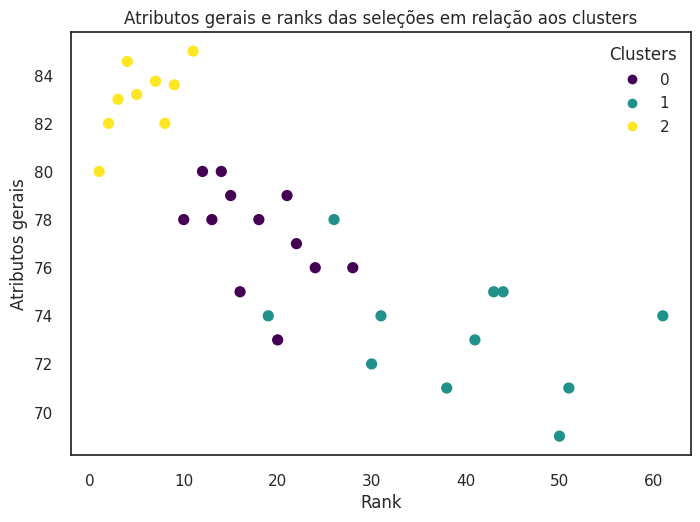

In [85]:
plot_df = cleaned_worls_cup_mean_df.copy()
plot_df = plot_df.reset_index()
display(plot_df)

scatter = plt.scatter(plot_df.iloc[:, 6], plot_df.iloc[:, 8], c=k_means_pred, s=50, cmap='viridis')
plt.title("Atributos gerais e ranks das seleções em relação aos clusters")
plt.xlabel("Rank")
plt.ylabel("Atributos gerais")
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.show()

In [86]:
plot_df[['team', 'cluster_result']].sort_values('cluster_result')

,team,cluster_result
7,Croatia,0
14,IR Iran,0
15,Japan,0
8,Denmark,0
30,Uruguay,0
18,Morocco,0
17,Mexico,0
16,Korea Republic,0
24,Senegal,0
25,Serbia,0


# Regressão Linear (Newton)

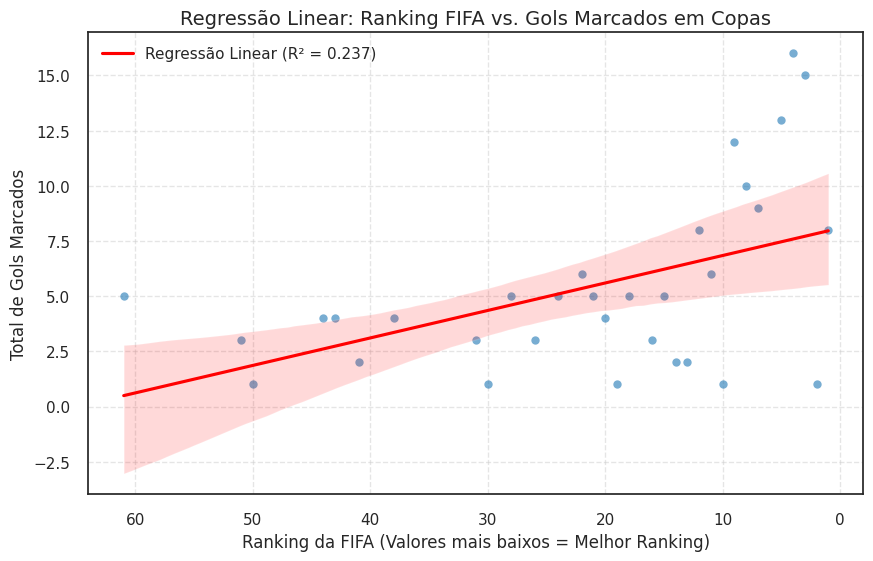

--- Métricas da Regressão Linear ---
Coeficiente de Determinação (R²): 0.2370
Coeficiente Angular (Inclinação da reta): -0.1245


In [87]:
df_base = df.copy()

# Isolar apenas os jogos da Copa do Mundo
df_wc = df_base[df_base['tournament'] == 'FIFA World Cup'].copy()

# Reestruturar os dados para o nível de "Equipe por Jogo"

# Isolamos os mandantes
home_df = df_wc[['home_team', 'home_score', 'home_Rank']].rename(columns={
    'home_team': 'team',
    'home_score': 'goals',
    'home_Rank': 'rank'
})

# Isolamos os visitantes (away)
away_df = df_wc[['away_team', 'away_score', 'away_Rank']].rename(columns={
    'away_team': 'team',
    'away_score': 'goals',
    'away_Rank': 'rank'
})

# Concatenamos ambos para criar uma visão única
df_stacked = pd.concat([home_df, away_df], ignore_index=True)

# Agregação em Nível de Torneio (Total de gols por equipe)

# Calculamos a média do ranking da equipe e a soma de todos os gols que ela marcou
df_regressao = df_stacked.groupby('team').agg({
    'rank': 'mean',   # O Ranking FIFA médio da equipe (variável independente X)
    'goals': 'sum'    # Total de gols marcados na competição (variável dependente y)
}).reset_index()

# Remover quaisquer valores nulos que possam ter surgido
df_regressao = df_regressao.dropna()

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import seaborn as sns
import matplotlib.pyplot as plt

# Separar Variáveis
X = df_regressao[['rank']] # O Scikit-learn exige um formato 2D para o X
y = df_regressao['goals']  # Array 1D para o y

# Treinar o modelo de Regressão Linear
modelo_reg = LinearRegression()
modelo_reg.fit(X, y)

# Previsões para calcular o R²
y_pred = modelo_reg.predict(X)
r2 = r2_score(y, y_pred)
coef_angular = modelo_reg.coef_[0]

# Configurar o gráfico Seaborn
plt.figure(figsize=(10, 6))

# Usar regplot do Seaborn para plotar a dispersão e a reta de regressão
sns.regplot(data=df_regressao, x='rank', y='goals',
            scatter_kws={'alpha': 0.6, 'color': '#1f77b4'},
            line_kws={'color': 'red', 'label': f'Regressão Linear (R² = {r2:.3f})'})

# Ajustes visuais
plt.title('Regressão Linear: Ranking FIFA vs. Gols Marcados em Copas', fontsize=14)
plt.xlabel('Ranking da FIFA (Valores mais baixos = Melhor Ranking)', fontsize=12)
plt.ylabel('Total de Gols Marcados', fontsize=12)

# Inverter o eixo X para ser mais intuitivo (Ranking 1 à direita e ranking 80 à esquerda)
# Assim, "melhor equipe" fica no lado direito do gráfico
plt.gca().invert_xaxis()

plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Imprimir as métricas estatísticas para análise
print(f"--- Métricas da Regressão Linear ---")
print(f"Coeficiente de Determinação (R²): {r2:.4f}")
print(f"Coeficiente Angular (Inclinação da reta): {coef_angular:.4f}")